Objective -To predict the Brake Power of a water pump using PINN model.


DATA UNDERSTANDING AND AUDIT

In [1]:
import pandas as pd
import numpy as np
df = pd.read_excel("PumpData_0.005.xlsx")
df.head()
df.shape
df.columns
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 313 entries, 0 to 312
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Water Flow             313 non-null    object
 1   Water inlet Pressure   313 non-null    object
 2   Water outlet pressure  313 non-null    object
 3   Water Density          313 non-null    object
 4   Pump Brake power       313 non-null    object
 5   Pump efficiency        313 non-null    object
dtypes: object(6)
memory usage: 14.8+ KB


In [2]:
df.isnull().sum()

Water Flow               0
Water inlet Pressure     0
Water outlet pressure    0
Water Density            0
Pump Brake power         0
Pump efficiency          0
dtype: int64

In [3]:
df.describe()

,Water Flow,Water inlet Pressure,Water outlet pressure,Water Density,Pump Brake power,Pump efficiency
count,313,313.000,313,313.0,313,313
unique,27,2.000,13,2.0,307,2
top,500,6.013,25,999.9,-32800,75
freq,12,312.000,26,312.0,2,312


In [4]:
df.nunique()

Water Flow                27
Water inlet Pressure       2
Water outlet pressure     13
Water Density              2
Pump Brake power         307
Pump efficiency            2
dtype: int64

EDA AND PHYSICAL ANALYSIS


In [5]:
#removing unit rows
df = df.iloc[1:].copy()

In [6]:
#converting data to numeric
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [7]:
#removing invalid brake power rows
print("Invalid Brake Power rows:")
print(df[df["Pump Brake power"] <= 0][["Water Flow",
        "Water inlet Pressure",
        "Water outlet pressure",
        "Water Density","Pump Brake power"]])
df = df[df["Pump Brake power"] > 0].copy()
print("Dataset shape after cleaning:", df.shape)

Invalid Brake Power rows:
     Water Flow  Water inlet Pressure  Water outlet pressure  Water Density  \
73         6500                 6.013                     25          999.9   
229       19500                 6.013                     25          999.9   

     Pump Brake power  
73           -32800.0  
229          -32800.0  
Dataset shape after cleaning: (310, 6)


In [8]:
#reseting the index
df.reset_index(drop=True, inplace=True)

In [9]:
#stats analysis
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Water Flow,310.0,13000.000000,7.518155e+03,500.0000,6500.000,13000.000,19500.000,25500.000
Water inlet Pressure,310.0,6.013000,8.896144e-16,6.0130,6.013,6.013,6.013,6.013
Water outlet pressure,310.0,163.387097,8.600620e+01,25.0000,100.000,175.000,243.750,300.000
Water Density,310.0,999.900000,1.138706e-13,999.9000,999.900,999.900,999.900,999.900
Pump Brake power,310.0,131.739117,1.127125e+02,0.6113,38.500,101.025,199.100,482.700
Pump efficiency,310.0,75.000000,0.000000e+00,75.0000,75.000,75.000,75.000,75.000


In [10]:
#checking unique values
for col in df.columns:
    print(f"\n{col}")
    print(df[col].unique())


Water Flow
[  500  1500  2500  3500  4500  5500  6500  7500  8500  9500 10500 11500
 12500 13500 14500 15500 16500 17500 18500 19500 20500 21500 22500 23500
 24500 25500]

Water inlet Pressure
[6.013]

Water outlet pressure
[ 25  50  75 100 125 150 175 200 225 250 275 300]

Water Density
[999.9]

Pump Brake power
[  0.6113   1.416    2.221    3.026    3.831    4.636    5.441    6.246
   7.05     7.855    8.66     9.465    1.834    4.249    6.663    9.078
  11.49    13.91    16.32    18.74    21.15    23.57    25.98    28.4
   3.056    7.081   11.11    15.13    19.15    23.18    27.2     31.23
  35.25    39.28    43.3     47.33     4.279    9.913   15.55    21.18
  26.82    32.45    38.08    43.72    49.35    54.99    60.62    66.26
   5.502   12.75    19.99    27.23    34.48    41.72    48.97    56.21
  63.45    70.7     77.94    85.19     6.724   15.58    24.43    33.29
  42.14    50.99    59.85    68.7     77.56    86.41    95.26   104.1
  18.41    28.87    39.34    49.8     60.27  

In [11]:
#checking duplicates
duplicate_rows = df[df.duplicated(keep=False)]
print(duplicate_rows)
print("Number of duplicate rows:", df.duplicated().sum())

Empty DataFrame
Columns: [Water Flow, Water inlet Pressure, Water outlet pressure, Water Density, Pump Brake power, Pump efficiency]
Index: []
Number of duplicate rows: 0


In [12]:
#IQR Outliers analysis
def detect_iqr_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = data[(data[column] < lower_bound) |(data[column] > upper_bound)]
    return outliers, lower_bound, upper_bound
    
for col in df.columns:
    outliers, lower, upper = detect_iqr_outliers(df,col)
    print("\n", "="*50)
    print("Column:", col)
    print("Q1:", df[col].quantile(0.25))
    print("Q3:", df[col].quantile(0.75))
    print("IQR:", df[col].quantile(0.75) - df[col].quantile(0.25))
    print("Lower Bound:", lower)
    print("Upper Bound:", upper)
    print("Number of Outliers:", len(outliers))


Column: Water Flow
Q1: 6500.0
Q3: 19500.0
IQR: 13000.0
Lower Bound: -13000.0
Upper Bound: 39000.0
Number of Outliers: 0

Column: Water inlet Pressure
Q1: 6.013
Q3: 6.013
IQR: 0.0
Lower Bound: 6.013
Upper Bound: 6.013
Number of Outliers: 0

Column: Water outlet pressure
Q1: 100.0
Q3: 243.75
IQR: 143.75
Lower Bound: -115.625
Upper Bound: 459.375
Number of Outliers: 0

Column: Water Density
Q1: 999.9
Q3: 999.9
IQR: 0.0
Lower Bound: 999.9
Upper Bound: 999.9
Number of Outliers: 0

Column: Pump Brake power
Q1: 38.5
Q3: 199.1
IQR: 160.6
Lower Bound: -202.39999999999998
Upper Bound: 440.0
Number of Outliers: 4

Column: Pump efficiency
Q1: 75.0
Q3: 75.0
IQR: 0.0
Lower Bound: 75.0
Upper Bound: 75.0
Number of Outliers: 0


In [13]:
#suspicious brake power values
suspicious = df[df["Pump Brake power"] <= 0]
print(suspicious[["Water Flow","Water inlet Pressure","Water outlet pressure","Water Density","Pump Brake power"]])

Empty DataFrame
Columns: [Water Flow, Water inlet Pressure, Water outlet pressure, Water Density, Pump Brake power]
Index: []


ML Model

In [14]:
#Defining features and target
features = ["Water Flow",
    "Water inlet Pressure",
    "Water outlet pressure",
    "Water Density"]
target = "Pump Brake power"

In [15]:
#creating x and y
X = df[features].copy()
y = df[target].copy()
print("Input features:")
print(X.head())
print("\nTarget:")
print(y.head())

Input features:
   Water Flow  Water inlet Pressure  Water outlet pressure  Water Density
0         500                 6.013                     25          999.9
1         500                 6.013                     50          999.9
2         500                 6.013                     75          999.9
3         500                 6.013                    100          999.9
4         500                 6.013                    125          999.9

Target:
0    0.6113
1    1.4160
2    2.2210
3    3.0260
4    3.8310
Name: Pump Brake power, dtype: float64


In [16]:
#train test split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training target statistics:")
print(y_train.describe())
print("\nTesting target statistics:")
print(y_test.describe())

Training samples: 248
Testing samples: 62
Training target statistics:
count    248.000000
mean     135.900735
std      113.773409
min        0.611300
25%       41.125000
50%      103.750000
75%      213.275000
max      482.700000
Name: Pump Brake power, dtype: float64

Testing target statistics:
count     62.000000
mean     115.092645
std      107.644626
min        3.026000
25%       34.487500
50%       76.215000
75%      156.075000
max      444.900000
Name: Pump Brake power, dtype: float64


Physics Calculations

In [17]:
#physics variables

# Mass flow rate
df["Mass Flow (kg/s)"] = (df["Water Flow"] / 3600)
print(df["Mass Flow (kg/s)"].head())

#volumetric flow
df["Flow (m3/s)"] = (df["Mass Flow (kg/s)"] /df["Water Density"])
print(df["Flow (m3/s)"].head())

#pressure difference
df["Delta P (bar)"] = (df["Water outlet pressure"] -df["Water inlet Pressure"])
print(df["Delta P (bar)"].head())

#converting pressure into pascal
df["Delta P (Pa)"] = (df["Delta P (bar)"] * 100000)
print(df["Delta P (Pa)"].head())

# Hydraulic power in Watts
df["Hydraulic Power (W)"] = (df["Flow (m3/s)"] *df["Delta P (Pa)"])
print(df["Hydraulic Power (W)"].head())

# Hydraulic power in kW
df["Hydraulic Power (kW)"] = (df["Hydraulic Power (W)"] / 1000)
print(df["Hydraulic Power (kW)"].head())

0    0.138889
1    0.138889
2    0.138889
3    0.138889
4    0.138889
Name: Mass Flow (kg/s), dtype: float64
0    0.000139
1    0.000139
2    0.000139
3    0.000139
4    0.000139
Name: Flow (m3/s), dtype: float64
0     18.987
1     43.987
2     68.987
3     93.987
4    118.987
Name: Delta P (bar), dtype: float64
0     1898700.0
1     4398700.0
2     6898700.0
3     9398700.0
4    11898700.0
Name: Delta P (Pa), dtype: float64
0     263.734707
1     610.991655
2     958.248603
3    1305.505551
4    1652.762498
Name: Hydraulic Power (W), dtype: float64
0    0.263735
1    0.610992
2    0.958249
3    1.305506
4    1.652762
Name: Hydraulic Power (kW), dtype: float64


In [18]:
#physics variables description
physics_columns = ["Mass Flow (kg/s)",
    "Flow (m3/s)",
    "Delta P (bar)",
    "Delta P (Pa)",
    "Hydraulic Power (W)",
    "Hydraulic Power (kW)"]
print(df[physics_columns].describe())

       Mass Flow (kg/s)  Flow (m3/s)  Delta P (bar)  Delta P (Pa)  \
count        310.000000   310.000000     310.000000  3.100000e+02   
mean           3.611111     0.003611     157.374097  1.573741e+07   
std            2.088376     0.002089      86.006200  8.600620e+06   
min            0.138889     0.000139      18.987000  1.898700e+06   
25%            1.805556     0.001806      93.987000  9.398700e+06   
50%            3.611111     0.003611     168.987000  1.689870e+07   
75%            5.416667     0.005417     237.737000  2.377370e+07   
max            7.083333     0.007084     293.987000  2.939870e+07   

       Hydraulic Power (W)  Hydraulic Power (kW)  
count           310.000000            310.000000  
mean          56835.218468             56.835218  
std           48626.702651             48.626703  
min             263.734707              0.263735  
25%           16608.890056             16.608890  
50%           43589.400607             43.589401  
75%           85889.9

In [19]:
#physics sanity check
print("Negative hydraulic power:",
      (df["Hydraulic Power (kW)"] < 0).sum())
print("Minimum hydraulic power:",
      df["Hydraulic Power (kW)"].min())
print("Maximum hydraulic power:",
      df["Hydraulic Power (kW)"].max())

Negative hydraulic power: 0
Minimum hydraulic power: 0.2637347068040138
Maximum hydraulic power: 208.26161782844954


PINN MODEL

In [20]:
#preparing inputs
X = df[features].copy()
y = df["Pump Brake power"].copy()

In [21]:
#train test split
from sklearn.model_selection import train_test_split
# Split dataframe indices
train_idx, test_idx = train_test_split(df.index,test_size=0.2,random_state=42)
# Create corresponding train/test dataframes
train_df = df.loc[train_idx].copy()
test_df = df.loc[test_idx].copy()
print("Training samples:", len(train_df))
print("Testing samples:", len(test_df))

Training samples: 248
Testing samples: 62


In [22]:
#recreating x and y 
features = ["Water Flow",
    "Water inlet Pressure",
    "Water outlet pressure",
    "Water Density"]

target = "Pump Brake power"
X_train = train_df[features].copy()
X_test = test_df[features].copy()
y_train = train_df[target].copy()
y_test = test_df[target].copy()
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (248, 4)
X_test shape: (62, 4)
y_train shape: (248,)
y_test shape: (62,)


In [23]:
#preparing hydraulic power tensors
hydraulic_train = train_df["Hydraulic Power (kW)"].values.reshape(-1, 1)
hydraulic_test = test_df["Hydraulic Power (kW)"].values.reshape(-1, 1)

In [24]:
#converting data to pytorch tensors
import torch
hydraulic_train_tensor = torch.tensor(hydraulic_train,dtype=torch.float32)
hydraulic_test_tensor = torch.tensor(hydraulic_test,dtype=torch.float32)
print("Hydraulic train tensor shape:",hydraulic_train_tensor.shape)
print("Hydraulic test tensor shape:",hydraulic_test_tensor.shape)

Hydraulic train tensor shape: torch.Size([248, 1])
Hydraulic test tensor shape: torch.Size([62, 1])


In [25]:
#scaling inputs
from sklearn.preprocessing import StandardScaler
scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

In [26]:
#converting into tensors
X_train_tensor = torch.tensor(X_train_scaled,dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled,dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values.reshape(-1, 1),dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values.reshape(-1, 1),dtype=torch.float32)

In [27]:
#creating neural network
import torch
import torch.nn as nn
class PumpPINN(nn.Module):
    def __init__(self):
        super(PumpPINN, self).__init__()
        # Shared neural network
        self.shared = nn.Sequential(
            nn.Linear(4, 32),
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 16),
            nn.Tanh())
        # Output 1: Brake Power
        self.brake_power_head = nn.Linear(16, 1)
        # Output 2: Efficiency
        self.efficiency_head = nn.Linear(16, 1)
    def forward(self, x):
        features = self.shared(x)
        # Brake Power prediction
        brake_power = self.brake_power_head(features)
        # Efficiency constrained between 0 and 1
        efficiency = torch.sigmoid(self.efficiency_head(features))
        return brake_power, efficiency

In [28]:
# defining loss function
import torch
import torch.nn as nn
mse_loss = nn.MSELoss()

def pinn_loss(predicted_brake_power,actual_brake_power,predicted_efficiency,hydraulic_power,lambda_physics=1.0):
    # Data Loss
    data_loss = mse_loss(predicted_brake_power,actual_brake_power)
    #Physics loss
    physics_brake_relation = (predicted_brake_power *predicted_efficiency)
    physics_loss = mse_loss(physics_brake_relation,hydraulic_power)
    #Total Loss
    total_loss = (data_loss +lambda_physics * physics_loss)
    return (total_loss,data_loss,physics_loss)

In [29]:
model = PumpPINN()
optimizer = torch.optim.Adam(model.parameters(),lr=0.005)
lambda_physics = 1.0

In [30]:
#training the PINN
epochs = 5000

loss_history = []
data_loss_history = []
physics_loss_history = []

for epoch in range(epochs):
    # Clear gradients
    optimizer.zero_grad()
    # Neural Network Prediction
    predicted_brake_power, predicted_efficiency = model(X_train_tensor)
    # Calculate PINN Loss
    total_loss, data_loss, physics_loss = pinn_loss(predicted_brake_power,y_train_tensor,predicted_efficiency,hydraulic_train_tensor,lambda_physics)
    # Backpropagation
    total_loss.backward()
    optimizer.step()
    # Store Losses
    loss_history.append(total_loss.item())
    data_loss_history.append(data_loss.item())
    physics_loss_history.append(physics_loss.item())
    # Display Progress
    if (epoch + 1) % 500 == 0:
        print(f"Epoch [{epoch+1}/{epochs}] | "
            f"Total Loss: {total_loss.item():.6f} | "
            f"Data Loss: {data_loss.item():.6f} | "
            f"Physics Loss: {physics_loss.item():.6f}")

Epoch [500/5000] | Total Loss: 24013.804688 | Data Loss: 21626.068359 | Physics Loss: 2387.735352
Epoch [1000/5000] | Total Loss: 16787.007812 | Data Loss: 15777.435547 | Physics Loss: 1009.572571
Epoch [1500/5000] | Total Loss: 12144.576172 | Data Loss: 11735.989258 | Physics Loss: 408.586548
Epoch [2000/5000] | Total Loss: 8948.172852 | Data Loss: 8782.930664 | Physics Loss: 165.241959
Epoch [2500/5000] | Total Loss: 6633.834473 | Data Loss: 6562.391602 | Physics Loss: 71.442841
Epoch [3000/5000] | Total Loss: 4922.732422 | Data Loss: 4876.336426 | Physics Loss: 46.395958
Epoch [3500/5000] | Total Loss: 3616.513184 | Data Loss: 3596.307373 | Physics Loss: 20.205772
Epoch [4000/5000] | Total Loss: 2646.720215 | Data Loss: 2631.789551 | Physics Loss: 14.930673
Epoch [4500/5000] | Total Loss: 1941.273438 | Data Loss: 1917.713989 | Physics Loss: 23.559488
Epoch [5000/5000] | Total Loss: 1398.512817 | Data Loss: 1392.882080 | Physics Loss: 5.630721


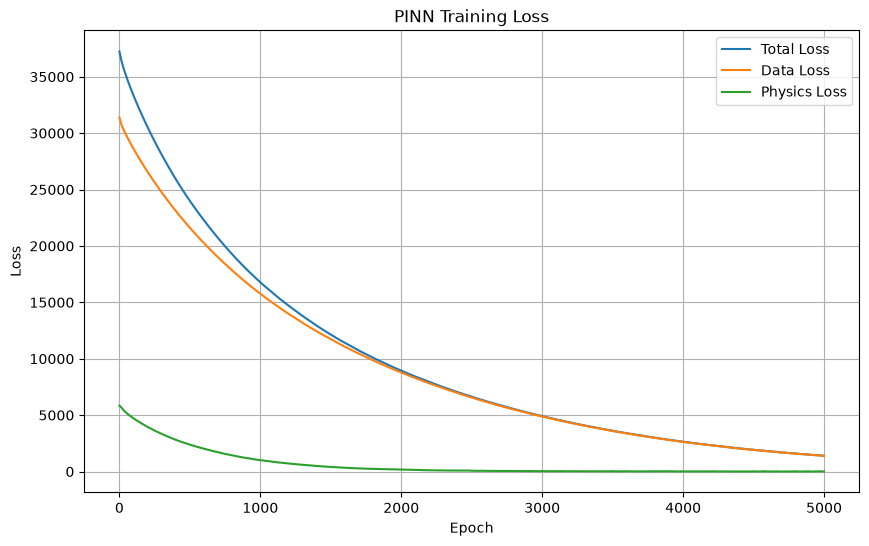

In [31]:
#plotting traning losses
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(loss_history,label="Total Loss")
plt.plot(data_loss_history,label="Data Loss")
plt.plot(physics_loss_history,label="Physics Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("PINN Training Loss")
plt.legend()
plt.grid(True)
plt.show()

In [32]:
#learned efficiency stats
model.eval()
with torch.no_grad():
    predicted_brake_train, predicted_efficiency_train = model(X_train_tensor)
print("Efficiency Statistics")
print("Minimum:",predicted_efficiency_train.min().item())
print("Maximum:",predicted_efficiency_train.max().item())
print("Mean:",predicted_efficiency_train.mean().item())

Efficiency Statistics
Minimum: 0.3464752435684204
Maximum: 0.6895908117294312
Mean: 0.45028001070022583


In [33]:
#physics consistency
with torch.no_grad():
    physics_power = (predicted_brake_train *
        predicted_efficiency_train)
physics_error = (physics_power -hydraulic_train_tensor)
print("Mean absolute physics error:",
    torch.mean(torch.abs(physics_error)).item())

Mean absolute physics error: 0.7452082633972168


Model Evaluation

In [34]:
#predictions
model.eval()
with torch.no_grad():
    predicted_brake_test, predicted_efficiency_test = model(X_test_tensor)
print("Predicted Brake Power:")
print(predicted_brake_test[:10])
print("\nPredicted Efficiency:")
print(predicted_efficiency_test[:10])    

Predicted Brake Power:
tensor([[148.0870],
        [  8.4917],
        [ 70.8270],
        [  7.3079],
        [  7.2231],
        [ 33.8639],
        [117.9529],
        [143.8648],
        [221.6591],
        [ 60.4744]])

Predicted Efficiency:
tensor([[0.4327],
        [0.4283],
        [0.4280],
        [0.4076],
        [0.4008],
        [0.4312],
        [0.4336],
        [0.4291],
        [0.4320],
        [0.4281]])


In [35]:
#converting pytorch tensors into numpy
y_test_actual = y_test_tensor.numpy().flatten()
y_test_predicted = predicted_brake_test.numpy().flatten()
efficiency_test_predicted = (predicted_efficiency_test.numpy().flatten())

In [36]:
#evaluation matrix
import numpy as np
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

mae = mean_absolute_error(y_test_actual,y_test_predicted)
print("MAE:", mae, "kW")

rmse = np.sqrt(mean_squared_error(y_test_actual,y_test_predicted))
print("RMSE:", rmse, "kW")

r2 = r2_score(y_test_actual,y_test_predicted)
print("R²:", r2)

MAE: 11.131688117980957 kW
RMSE: 38.53422313397615 kW
R²: 0.8697521686553955


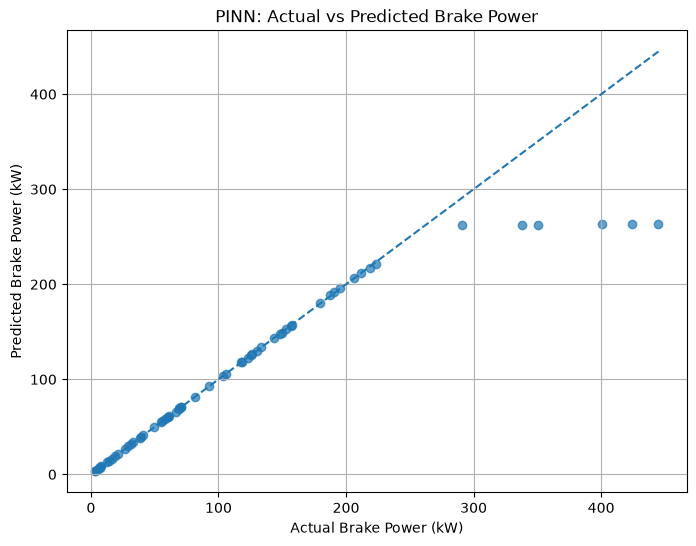

In [37]:
#actual vs predicted brake power
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))
plt.scatter(y_test_actual,y_test_predicted,alpha=0.7)
# Perfect prediction line
min_value = min(y_test_actual.min(),y_test_predicted.min())
max_value = max(y_test_actual.max(),y_test_predicted.max())
plt.plot([min_value, max_value],
    [min_value, max_value],
    linestyle="--")
plt.xlabel("Actual Brake Power (kW)")
plt.ylabel("Predicted Brake Power (kW)")
plt.title("PINN: Actual vs Predicted Brake Power")
plt.grid(True)
plt.show()

In [38]:
#residual analysis
residuals = (y_test_actual -y_test_predicted)
print("Residual Mean:", residuals.mean())
print("Residual Std:", residuals.std())

Residual Mean: 10.7643
Residual Std: 37.000217


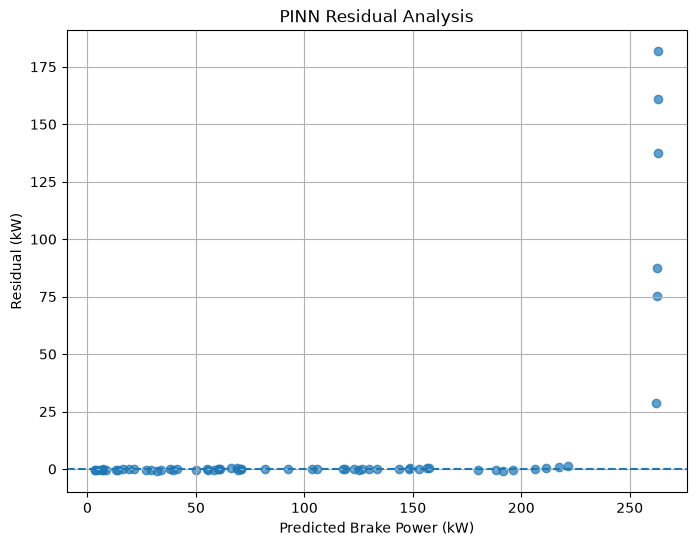

In [39]:
#residual plot
plt.figure(figsize=(8, 6))
plt.scatter(y_test_predicted,residuals,alpha=0.7)
plt.axhline(y=0,linestyle="--")
plt.xlabel("Predicted Brake Power (kW)")
plt.ylabel("Residual (kW)")
plt.title("PINN Residual Analysis")
plt.grid(True)
plt.show()

In [40]:
#PINN efficiency stats
print("PINN Efficiency Statistics")
print("--------------------------")
print("Minimum:",efficiency_test_predicted.min())
print("Maximum:",efficiency_test_predicted.max())
print("Mean:",efficiency_test_predicted.mean())

PINN Efficiency Statistics
--------------------------
Minimum: 0.37844193
Maximum: 0.6895877
Mean: 0.4477189


### Feature importance (brake-power head)

Permutation importance on the **test set**: how much brake-power MAE rises if a scaled operating input is shuffled. Hydraulic power is not a network input, so it is not included. Inlet pressure and density barely vary in this file, so their importance is expected to be near zero.

c:\Users\krish\.conda\envs\water_pump\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\krish\.conda\envs\water_pump\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\krish\.conda\envs\water_pump\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\krish\.conda\envs\water_pump\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\krish\.conda\envs\water_pump\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with f

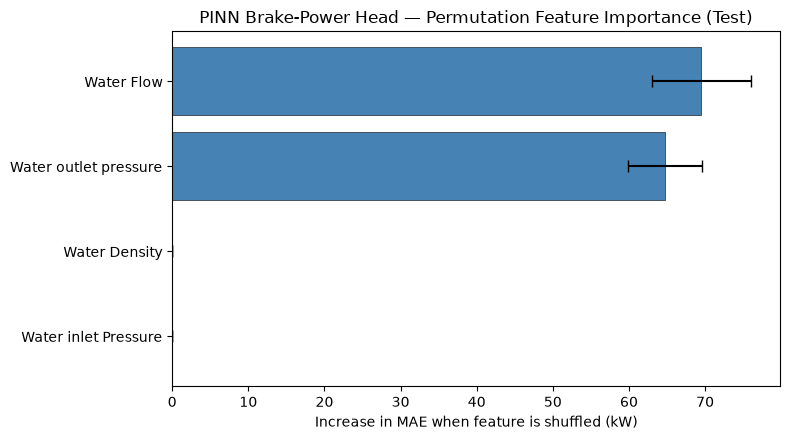

Baseline test MAE: 11.1317 kW
Permutation importance (mean MAE increase)
Water Flow               69.500461
Water outlet pressure    64.751024
Water Density             0.000000
Water inlet Pressure      0.000000


In [41]:
def pinn_brake_mae(X_scaled, y_true):
    model.eval()
    with torch.no_grad():
        x_tensor = torch.tensor(X_scaled, dtype=torch.float32)
        brake_pred, _ = model(x_tensor)
    return mean_absolute_error(y_true, brake_pred.numpy().flatten())


y_true_test = y_test.values
base_mae = pinn_brake_mae(X_test_scaled, y_true_test)

n_repeats = 30
rng = np.random.default_rng(42)
X_test_np = X_test[features].to_numpy().copy()
perm_scores = {col: [] for col in features}

for col_i, col in enumerate(features):
    for _ in range(n_repeats):
        X_perm = X_test_np.copy()
        rng.shuffle(X_perm[:, col_i])
        X_perm_scaled = scaler_X.transform(X_perm)
        perm_scores[col].append(pinn_brake_mae(X_perm_scaled, y_true_test) - base_mae)

importance = pd.Series({col: np.mean(vals) for col, vals in perm_scores.items()}).sort_values()
importance_std = pd.Series({col: np.std(vals) for col, vals in perm_scores.items()}).loc[importance.index]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(
    importance.index,
    importance.values,
    xerr=importance_std.values,
    color="steelblue",
    edgecolor="k",
    linewidth=0.4,
    capsize=4,
)
ax.set_xlabel("Increase in MAE when feature is shuffled (kW)")
ax.set_title("PINN Brake-Power Head \u2014 Permutation Feature Importance (Test)")
plt.tight_layout()
plt.show()

print(f"Baseline test MAE: {base_mae:.4f} kW")
print("Permutation importance (mean MAE increase)")
print(importance.sort_values(ascending=False).to_string())
